In [5]:
import os
import sys
import importlib

import tensorflow as tf
import pandas as pd
import numpy as np

project_root = os.path.abspath("..")

preprocessing_dir = os.path.join(
    project_root,
    "preprocessing"
)

models_dir = os.path.join(
    project_root,
    "models"
)

config_dir = os.path.join(
    project_root,
    "config"
)

for directory in [
    preprocessing_dir,
    models_dir,
    config_dir
]:
    if directory not in sys.path:
        sys.path.insert(0, directory)

import dataset_loader
import class_weights
import efficientnet_model
import train_model

importlib.reload(dataset_loader)
importlib.reload(class_weights)
importlib.reload(efficientnet_model)
importlib.reload(train_model)

print("All modules imported successfully!")

All modules imported successfully!


In [6]:
csv_path = "D:\\AI-Powered-Diabetic-Retinopathy-System\\ml-model\\dataset\\raw\\train.csv"

df = dataset_loader.load_metadata(csv_path)

image_dir = "D:\\AI-Powered-Diabetic-Retinopathy-System\\ml-model\\dataset\\raw\\train_images"

df = dataset_loader.create_image_paths(
    df,
    image_dir
)

df = dataset_loader.validate_image_paths(df)

print("Total images:", len(df))

Total images: 3662


In [7]:
train_df, validation_df, test_df = (
    dataset_loader.split_dataset(df)
)

print("Training:", len(train_df))
print("Validation:", len(validation_df))
print("Test:", len(test_df))

Training: 2563
Validation: 549
Test: 550


In [8]:
weights = class_weights.calculate_class_weights(
    train_df["diagnosis"].values
)

print("Class weights:")
print(weights)

Class weights:
{0: 0.4058590657165479, 1: 1.9791505791505792, 2: 0.7333333333333333, 3: 3.797037037037037, 4: 2.476328502415459}


In [9]:
train_dataset = dataset_loader.create_tf_dataset(
    train_df,
    batch_size=16,
    shuffle=True
)

validation_dataset = dataset_loader.create_tf_dataset(
    validation_df,
    batch_size=16,
    shuffle=False
)

test_dataset = dataset_loader.create_tf_dataset(
    test_df,
    batch_size=16,
    shuffle=False
)

In [13]:
import importlib
import efficientnet_model

importlib.reload(efficientnet_model)

print("Updated EfficientNet model module loaded!")

Updated EfficientNet model module loaded!


In [14]:
model = efficientnet_model.build_efficientnet_model()

model.summary()

NameError: name 'tensorflow' is not defined

In [12]:
model = train_model.compile_model(
    model,
    learning_rate=1e-3
)

print("Model compiled successfully!")

NameError: name 'model' is not defined

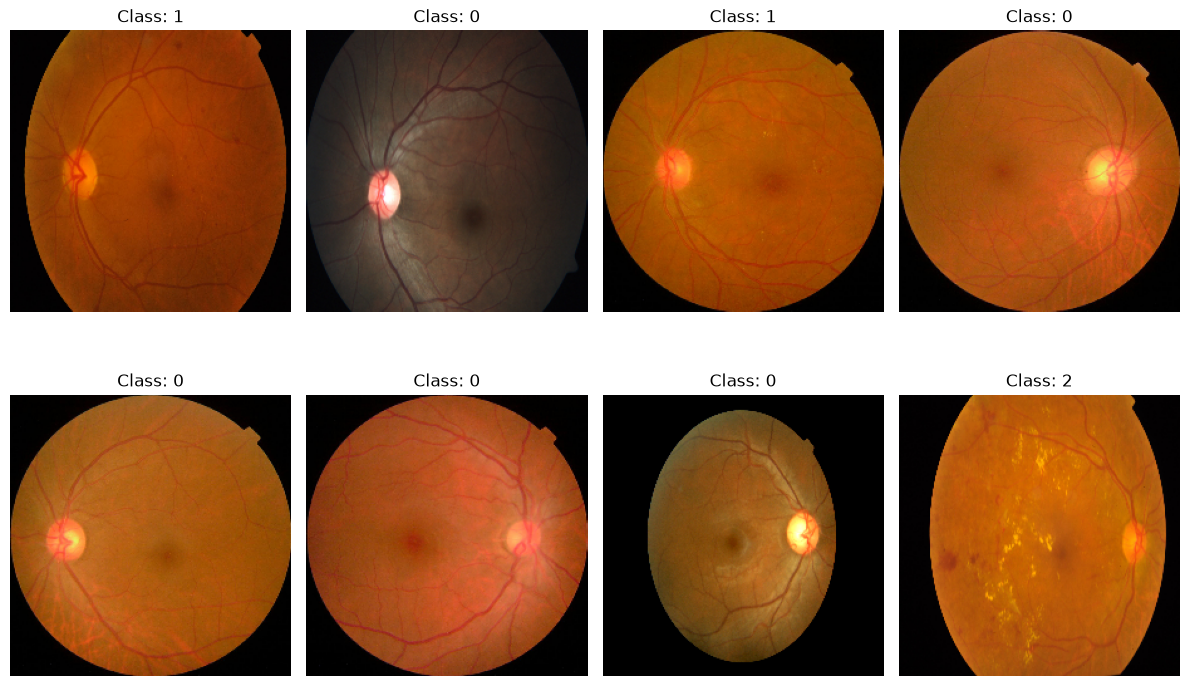

In [ ]:
import matplotlib.pyplot as plt

images, labels = next(iter(train_dataset))

plt.figure(figsize=(12, 8))

for i in range(8):
    plt.subplot(2, 4, i + 1)

    plt.imshow(
        images[i].numpy().astype("uint8")
    )

    plt.title(
        f"Class: {labels[i].numpy()}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
print("Minimum pixel value:", tf.reduce_min(images).numpy())
print("Maximum pixel value:", tf.reduce_max(images).numpy())

Minimum pixel value: 0.0
Maximum pixel value: 255.0


In [27]:
import callbacks
importlib.reload(callbacks)

<module 'callbacks' from 'd:\\AI-Powered-Diabetic-Retinopathy-System\\ml-model\\models\\callbacks.py'>

In [28]:
training_callbacks = callbacks.create_training_callbacks(
    "../saved_models/best_efficientnet.keras"
)

In [ ]:
history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=2,
    class_weight=weights,
    callbacks=training_callbacks
)

Epoch 1/2
161/161 ━━━━━━━━━━━━━━━━━━━━ 0s 549ms/step - accuracy: 0.5579 - loss: 1.3569
Epoch 1: val_loss improved from None to 0.86482, saving model to ../saved_models/best_efficientnet.keras

Epoch 1: finished saving model to ../saved_models/best_efficientnet.keras
161/161 ━━━━━━━━━━━━━━━━━━━━ 123s 735ms/step - accuracy: 0.5579 - loss: 1.3569 - val_accuracy: 0.6703 - val_loss: 0.8648 - learning_rate: 0.0010
Epoch 2/2
161/161 ━━━━━━━━━━━━━━━━━━━━ 0s 427ms/step - accuracy: 0.6625 - loss: 1.0963
Epoch 2: val_loss improved from 0.86482 to 0.86277, saving model to ../saved_models/best_efficientnet.keras

Epoch 2: finished saving model to ../saved_models/best_efficientnet.keras
161/161 ━━━━━━━━━━━━━━━━━━━━ 83s 508ms/step - accuracy: 0.6625 - loss: 1.0963 - val_accuracy: 0.6521 - val_loss: 0.8628 - learning_rate: 0.0010
Restoring model weights from the end of the best epoch: 2.


In [30]:
EPOCHS = 20

BATCH_SIZE = 16

LEARNING_RATE = 1e-3

In [31]:
model = efficientnet_model.build_efficientnet_model()

model = train_model.compile_model(
    model,
    learning_rate=LEARNING_RATE
)

model.summary()

NameError: name 'tensorflow' is not defined

In [32]:
training_callbacks = callbacks.create_training_callbacks(
    "../saved_models/best_efficientnet.keras"
)

In [ ]:
history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=EPOCHS,
    class_weight=weights,
    callbacks=training_callbacks
)

Epoch 1/20
 58/161 ━━━━━━━━━━━━━━━━━━━━ 40s 397ms/step - accuracy: 0.7608 - loss: 0.8440

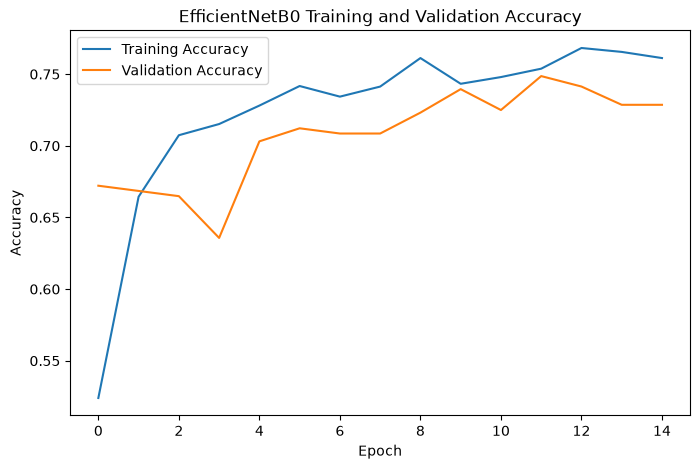

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("EfficientNetB0 Training and Validation Accuracy")
plt.legend()
plt.show()

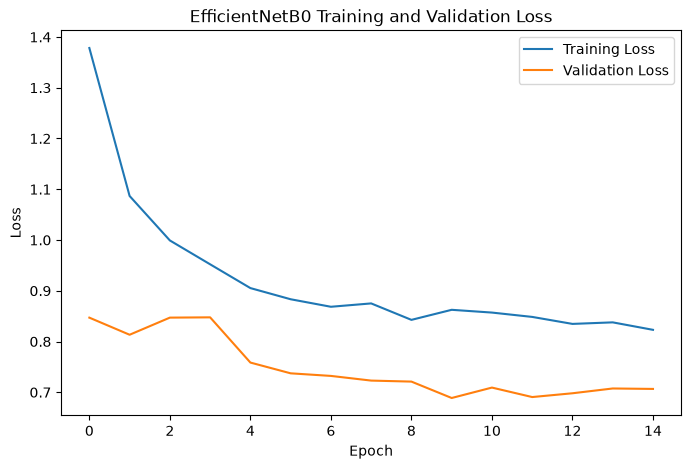

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("EfficientNetB0 Training and Validation Loss")
plt.legend()
plt.show()

In [ ]:
best_epoch = np.argmin(
    history.history["val_loss"]
) + 1

best_val_loss = min(
    history.history["val_loss"]
)

best_val_accuracy = max(
    history.history["val_accuracy"]
)

print("Best epoch:", best_epoch)
print("Best validation loss:", best_val_loss)
print("Best validation accuracy:", best_val_accuracy)

Best epoch: 10
Best validation loss: 0.688717246055603
Best validation accuracy: 0.748633861541748


In [48]:
import tensorflow as tf

best_model = tf.keras.models.load_model(
    "../saved_models/best_efficientnet.keras"
)

print("Best EfficientNetB0 model loaded successfully!")

Best EfficientNetB0 model loaded successfully!


In [49]:
test_loss, test_accuracy = best_model.evaluate(
    test_dataset,
    verbose=1
)

print("\nTest Results")
print("-" * 30)
print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

35/35 ━━━━━━━━━━━━━━━━━━━━ 17s 345ms/step - accuracy: 0.7455 - loss: 0.6650

Test Results
------------------------------
Test Loss: 0.6649963855743408
Test Accuracy: 0.7454545497894287


In [50]:
import numpy as np

y_true = []
y_pred = []

for images, labels in test_dataset:

    predictions = best_model.predict(
        images,
        verbose=0
    )

    predicted_classes = np.argmax(
        predictions,
        axis=1
    )

    y_true.extend(
        labels.numpy()
    )

    y_pred.extend(
        predicted_classes
    )

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print("Total test samples:", len(y_true))
print("Predictions generated successfully!")

Total test samples: 550
Predictions generated successfully!


In [51]:
class_names = [
    "No DR",
    "Mild DR",
    "Moderate DR",
    "Severe DR",
    "Proliferative DR"
]

In [52]:
from sklearn.metrics import classification_report
report = classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4
)

print(report)

                  precision    recall  f1-score   support

           No DR     0.9705    0.9705    0.9705       271
         Mild DR     0.5362    0.6607    0.5920        56
     Moderate DR     0.7677    0.5067    0.6104       150
       Severe DR     0.2609    0.4138    0.3200        29
Proliferative DR     0.3385    0.5000    0.4037        44

        accuracy                         0.7455       550
       macro avg     0.5747    0.6103    0.5793       550
    weighted avg     0.7830    0.7455    0.7541       550



In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_true,
    y_pred
)

print(cm)

[[263   7   1   0   0]
 [  3  37  10   2   4]
 [  4  22  76  22  26]
 [  0   1   3  12  13]
 [  1   2   9  10  22]]


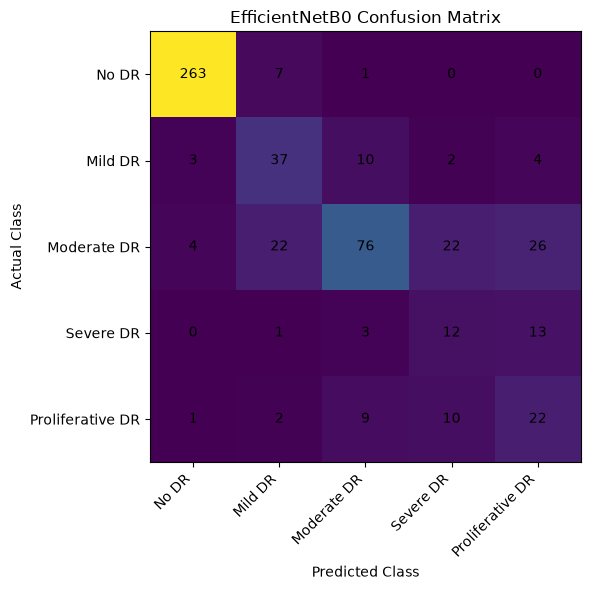

In [ ]:
plt.figure(figsize=(8, 6))

plt.imshow(cm)

plt.title("EfficientNetB0 Confusion Matrix")

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.xticks(
    range(len(class_names)),
    class_names,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(class_names)),
    class_names
)

for i in range(len(class_names)):
    for j in range(len(class_names)):
        plt.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center"
        )

plt.tight_layout()
plt.show()

In [15]:
best_model = tf.keras.models.load_model(
    "../saved_models/best_efficientnet.keras"
)

print("Baseline EfficientNetB0 loaded successfully!")

Baseline EfficientNetB0 loaded successfully!


In [16]:
print(
    "Total EfficientNet layers:",
    len(
        best_model.layers[1].layers
    )
)

Total EfficientNet layers: 238


In [17]:
for i, layer in enumerate(best_model.layers):
    print(i, layer.name, layer.trainable)

0 retinal_image True
1 efficientnetb0 False
2 global_average_pooling True
3 dropout True
4 dr_severity True


In [18]:
for layer in best_model.layers:
    print(
        layer.name,
        type(layer).__name__
    )

retinal_image InputLayer
efficientnetb0 Functional
global_average_pooling GlobalAveragePooling2D
dropout Dropout
dr_severity Dense


In [19]:
base_model = best_model.get_layer(
    "efficientnetb0"
)

print(
    "EfficientNet layers:",
    len(base_model.layers)
)

EfficientNet layers: 238


In [20]:
base_model = best_model.get_layer("efficientnetb0")

fine_tune_at = 180

# First freeze the entire backbone
base_model.trainable = True

# Freeze the earlier layers
for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

# Make later layers trainable
for layer in base_model.layers[fine_tune_at:]:
    layer.trainable = True

print("Fine-tuning configuration applied!")
print("Total EfficientNet layers:", len(base_model.layers))
print("Fine-tuning from layer:", fine_tune_at)

Fine-tuning configuration applied!
Total EfficientNet layers: 238
Fine-tuning from layer: 180


In [21]:
trainable_count = sum(
    layer.trainable
    for layer in base_model.layers
)

frozen_count = sum(
    not layer.trainable
    for layer in base_model.layers
)

print("Frozen layers:", frozen_count)
print("Trainable layers:", trainable_count)

Frozen layers: 180
Trainable layers: 58


In [22]:
for i in range(175, 185):
    print(
        i,
        base_model.layers[i].name,
        base_model.layers[i].trainable
    )

175 block6a_project_conv False
176 block6a_project_bn False
177 block6b_expand_conv False
178 block6b_expand_bn False
179 block6b_expand_activation False
180 block6b_dwconv True
181 block6b_bn True
182 block6b_activation True
183 block6b_se_squeeze True
184 block6b_se_reshape True


In [23]:
best_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model recompiled for fine-tuning!")

Model recompiled for fine-tuning!


In [24]:
best_model.summary()

Model: "EfficientNetB0_DR"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ retinal_image (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dr_severity (Dense)             │ (None, 5)              │         6,405 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,055,976 (15.47 MB)

 Trainable params: 2,676,165 (10.21 MB)

 Non-trainable params: 1,379,811 (5.26 MB)

In [35]:
finetune_callbacks = callbacks.create_training_callbacks(
    "../saved_models/best_efficientnet_finetuned.keras"
)

In [36]:
train_dataset_ft = dataset_loader.create_tf_dataset(
    train_df,
    batch_size=8,
    shuffle=True,
    training=True
)

validation_dataset_ft = dataset_loader.create_tf_dataset(
    validation_df,
    batch_size=8,
    shuffle=False,
    training=False
)

print("Fine-tuning datasets created successfully!")

Fine-tuning datasets created successfully!


In [37]:
fine_tune_history = best_model.fit(
    train_dataset_ft,
    validation_data=validation_dataset_ft,
    epochs=5,
    class_weight=weights,
    callbacks=finetune_callbacks
)

Epoch 1/5


d:\AI-Powered-Diabetic-Retinopathy-System\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


321/321 ━━━━━━━━━━━━━━━━━━━━ 0s 255ms/step - accuracy: 0.5759 - loss: 1.1985
Epoch 1: val_loss improved from None to 0.81106, saving model to ../saved_models/best_efficientnet_finetuned.keras

Epoch 1: finished saving model to ../saved_models/best_efficientnet_finetuned.keras
321/321 ━━━━━━━━━━━━━━━━━━━━ 116s 306ms/step - accuracy: 0.5759 - loss: 1.1985 - val_accuracy: 0.6685 - val_loss: 0.8111 - learning_rate: 1.0000e-05
Epoch 2/5
321/321 ━━━━━━━━━━━━━━━━━━━━ 0s 247ms/step - accuracy: 0.6293 - loss: 1.0910
Epoch 2: val_loss improved from 0.81106 to 0.78872, saving model to ../saved_models/best_efficientnet_finetuned.keras

Epoch 2: finished saving model to ../saved_models/best_efficientnet_finetuned.keras
321/321 ━━━━━━━━━━━━━━━━━━━━ 93s 289ms/step - accuracy: 0.6293 - loss: 1.0910 - val_accuracy: 0.6922 - val_loss: 0.7887 - learning_rate: 1.0000e-05
Epoch 3/5
321/321 ━━━━━━━━━━━━━━━━━━━━ 0s 240ms/step - accuracy: 0.6590 - loss: 1.0343
Epoch 3: val_loss did not improve from 0.78872
32

In [41]:
fine_tuned_model = tf.keras.models.load_model(
    "../saved_models/best_efficientnet_finetuned.keras"
)

print("Fine-tuned EfficientNetB0 loaded successfully!")

Fine-tuned EfficientNetB0 loaded successfully!


In [42]:
ft_test_loss, ft_test_accuracy = fine_tuned_model.evaluate(
    test_dataset,
    verbose=1
)

print("\nFine-Tuned Test Results")
print("-" * 35)
print("Test Loss:", ft_test_loss)
print("Test Accuracy:", ft_test_accuracy)

35/35 ━━━━━━━━━━━━━━━━━━━━ 18s 360ms/step - accuracy: 0.6964 - loss: 0.7541

Fine-Tuned Test Results
-----------------------------------
Test Loss: 0.754100501537323
Test Accuracy: 0.696363627910614


In [43]:
y_true_ft = []
y_pred_ft = []

for images, labels in test_dataset:

    predictions = fine_tuned_model.predict(
        images,
        verbose=0
    )

    predicted_classes = np.argmax(
        predictions,
        axis=1
    )

    y_true_ft.extend(labels.numpy())
    y_pred_ft.extend(predicted_classes)

y_true_ft = np.array(y_true_ft)
y_pred_ft = np.array(y_pred_ft)

print(
    "Total test samples:",
    len(y_true_ft)
)

Total test samples: 550


In [53]:
print(
    classification_report(
        y_true_ft,
        y_pred_ft,
        target_names=class_names,
        digits=4
    )
)

                  precision    recall  f1-score   support

           No DR     0.9774    0.9557    0.9664       271
         Mild DR     0.3786    0.6964    0.4906        56
     Moderate DR     0.7536    0.3467    0.4749       150
       Severe DR     0.2500    0.6207    0.3564        29
Proliferative DR     0.3659    0.3409    0.3529        44

        accuracy                         0.6964       550
       macro avg     0.5451    0.5921    0.5282       550
    weighted avg     0.7681    0.6964    0.7027       550

